In [40]:
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from files import data

In [22]:
# Make sure this matches project root every time

ROOT = 'SSU-Data-Dash-2026-Toronto-Home-Price-Prediction-Challenge'

if os.path.basename(os.getcwd()) != ROOT:
    os.chdir(ROOT)

os.environ["DATA_DIR"] = "datasets"

In [27]:
listings = data.load("listings")

off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [48]:
', '.join(listings.columns)

'ml_num, sold_price, list_price, date_listed, date_sold, days_on_market, house_type_name, house_style, bedrooms, washrooms, parking_total, garage, house_area, lot_front, lot_depth, municipality, community, latitude, longitude, external_avm_estimate, external_avm_estimate_date, remarks'

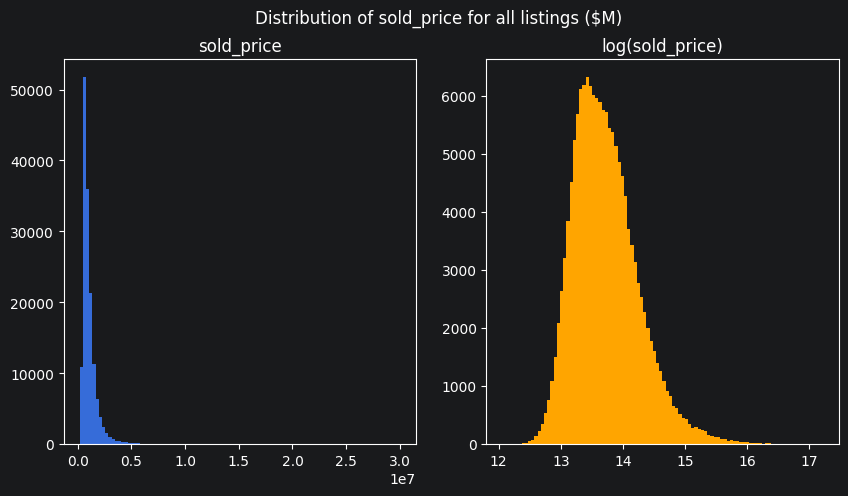

In [95]:
fig, axes = plt.subplots(1, 2, figsize = (10, 5))

axes[0].hist(listings['sold_price'], bins = 100)
axes[0].set(title = 'sold_price')

axes[1].hist(np.log(listings['sold_price']), bins = 100, color = 'orange')
axes[1].set(title = 'log(sold_price)')

plt.suptitle('Distribution of sold_price for all listings ($M)')
plt.show()

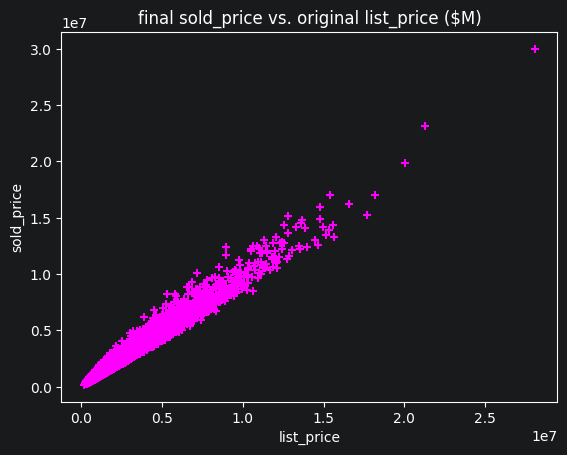

In [68]:
plt.scatter('list_price', 'sold_price', data = listings, marker = '+', color = 'magenta')

plt.title('final sold_price vs. original list_price ($M)')

plt.xlabel('list_price')
plt.ylabel('sold_price')

plt.show()

In [73]:
listings[['house_type_name', 'sold_price']].groupby('house_type_name').agg(
    {'sold_price': ['mean', 'median', 'var']}).round(2)

sold_price                         
                          mean     median           var
house_type_name                                        
Co-Op Apt            755315.64   646600.0  3.091575e+11
Condo Apt            699026.08   644300.0  7.695043e+10
Condo Townhouse      842632.68   786200.0  7.499725e+10
Detached            1688777.61  1367850.0  1.329696e+12
Freehold Townhouse  1283139.04  1146600.0  2.568131e+11
Semi-Detached       1322291.15  1179100.0  3.199281e+11

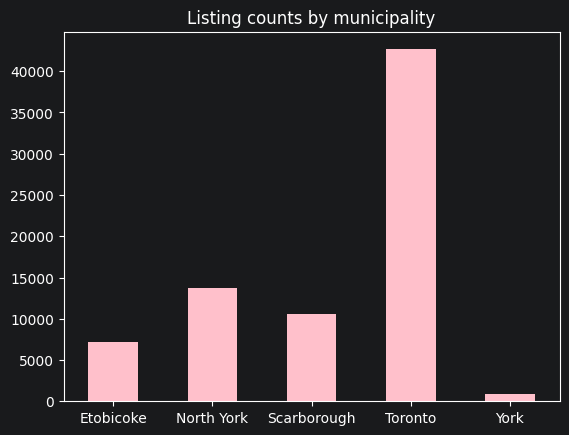

In [90]:
listings['municipality'].value_counts().sort_index().plot(kind = 'bar', rot = 0, color = 'pink')

plt.title('Listing counts by municipality')
plt.xlabel(None)

plt.show()